# 01 – Data Exploration
Goal: check the quality of the raw data and justify each preprocessing step.

In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.feature_selection import mutual_info_classif

SEED = 42
np.random.seed(SEED)

DATA_PATH = Path("../data/phishing.csv")
FIG_DIR = Path("../figures"); FIG_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 40)

## 1. Load and inspect

In [63]:
df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (11054, 32)


,Index,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,Favicon,NonStdPort,HTTPSDomainURL,RequestURL,AnchorURL,LinksInScriptTags,ServerFormHandler,InfoEmail,AbnormalURL,WebsiteForwarding,StatusBarCust,DisableRightClick,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
0,0,1,1,1,1,1,-1,0,1,-1,1,1,-1,1,0,-1,-1,1,1,0,1,1,1,1,-1,-1,0,-1,1,1,1,-1
1,1,1,0,1,1,1,-1,-1,-1,-1,1,1,-1,1,0,-1,-1,-1,-1,0,1,1,1,1,1,-1,1,-1,1,0,-1,-1
2,2,1,0,1,1,1,-1,-1,-1,1,1,1,-1,-1,0,0,-1,1,1,0,1,1,1,1,-1,-1,1,-1,1,-1,1,-1
3,3,1,0,-1,1,1,-1,1,1,-1,1,1,1,1,0,0,-1,1,1,0,-1,1,-1,1,-1,-1,0,-1,1,1,1,1
4,4,-1,0,-1,1,-1,-1,1,1,-1,1,1,-1,1,0,0,-1,-1,-1,0,1,1,1,1,1,1,1,-1,1,-1,-1,1


In [64]:
df = df_raw.drop(columns=["Index"])
FEATURES = [c for c in df.columns if c != "class"]
print(len(FEATURES), "features")

30 features


Index is only a row number, it is not a property of the website, therefore it is dropped.

## 2. Missing values and value ranges

In [65]:
print("Missing values:", df.isna().sum().sum())
pd.Series({c: sorted(df[c].unique()) for c in df.columns}, name="values").to_frame()

Missing values: 0


,values
UsingIP,"[-1, 1]"
LongURL,"[-1, 0, 1]"
ShortURL,"[-1, 1]"
Symbol@,"[-1, 1]"
Redirecting//,"[-1, 1]"
PrefixSuffix-,"[-1, 1]"
SubDomains,"[-1, 0, 1]"
HTTPS,"[-1, 0, 1]"
DomainRegLen,"[-1, 1]"
Favicon,"[-1, 1]"


We found no missing values which means that no imputation is needed. All features take values in {-1, 0, 1}, so there are no outliers.

## 3. Target distribution

class
legitimate    6157
phishing      4897
Name: count, dtype: int64
class
legitimate    0.557
phishing      0.443
Name: count, dtype: float64


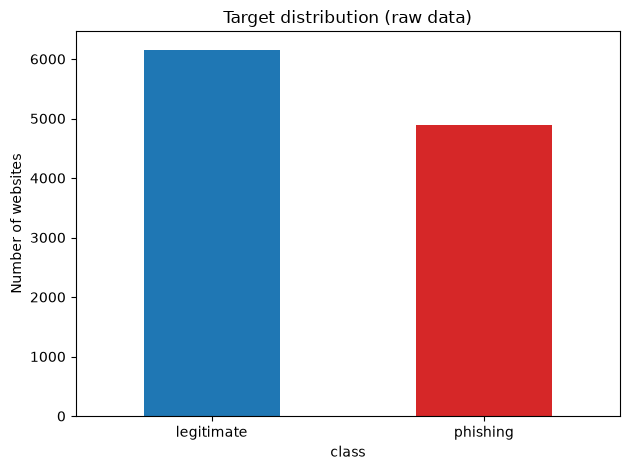

In [66]:
df["class"] = (df["class"] == -1).astype(int)

counts = df["class"].value_counts().rename({0: "legitimate", 1: "phishing"})
print(counts)
print((counts / len(df)).round(3))

ax = counts.plot.bar(color=["tab:blue", "tab:red"], rot=0)
ax.set_ylabel("Number of websites"); ax.set_title("Target distribution (raw data)")
plt.tight_layout(); plt.savefig(FIG_DIR / "target_distribution.png", dpi=150); plt.show()

The target is recoded so that 1 = phishing (positive class). The raw data is 56% legitimate / 44% phishing: only a mild imbalance.

## 4. Duplicates and conflicting labels

In [67]:
n_exact = df.duplicated().sum()
n_feat = df.duplicated(subset=FEATURES).sum()
n_conflict = (df.groupby(FEATURES)["class"].nunique() > 1).sum()

print("Exact duplicates (features + label):", n_exact)
print("Duplicated features only:", n_feat)
print("Feature combinations with both labels:", n_conflict)

df = df.drop_duplicates().reset_index(drop=True)
print("Shape after deduplication:", df.shape)
print(df["class"].value_counts(normalize=True).rename({0: "legitimate", 1: "phishing"}).round(3))

Exact duplicates (features + label): 5205
Duplicated features only: 5269
Feature combinations with both labels: 64
Shape after deduplication: (5849, 31)
class
phishing      0.516
legitimate    0.484
Name: proportion, dtype: float64


About 47% of the rows are exact duplicates. We removed them before splitting, otherwise the same website could be in both the training and the test set, which would inflate the scores.
The 64 conflicting combinations are kept because they reflect real ambiguity.
After deduplication, the classes are balanced (52% phishing / 48% legitimate).

## 5. Feature distributions

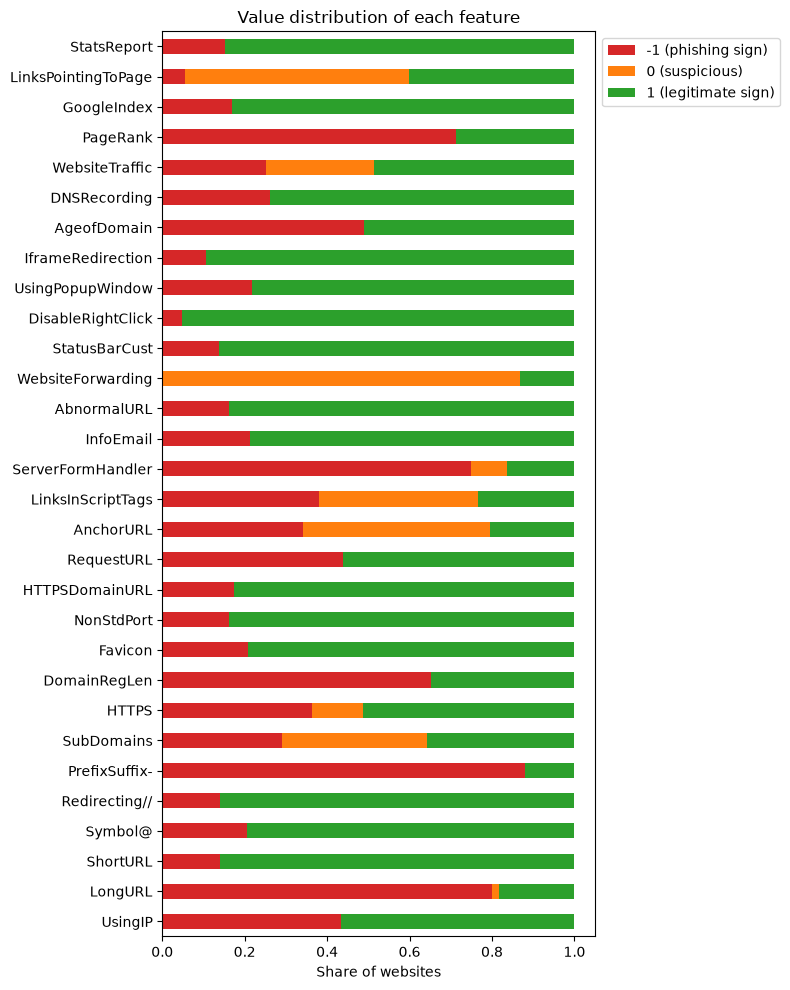

Almost constant features (>95%): ['DisableRightClick']


In [68]:
dist = (df[FEATURES].apply(lambda s: s.value_counts(normalize=True))
        .T.reindex(columns=[-1, 0, 1]).fillna(0))
ax = dist.plot.barh(stacked=True, figsize=(8, 10), color=["tab:red", "tab:orange", "tab:green"])
ax.set_xlabel("Share of websites"); ax.set_title("Value distribution of each feature")
ax.legend(["-1 (phishing sign)", "0 (suspicious)", "1 (legitimate sign)"],
          loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout(); plt.savefig(FIG_DIR / "feature_distributions.png", dpi=150); plt.show()

print("Almost constant features (>95%):", dist[dist.max(axis=1) > 0.95].index.tolist())

DisableRightClick is almost constant, and WebsiteForwarding only uses {0, 1} which means they carry little information.

## 6. Relevance of each feature

In [69]:
pearson = df[FEATURES].corrwith(df["class"])
mi = pd.Series(mutual_info_classif(df[FEATURES], df["class"], discrete_features=True,
                                   random_state=SEED), index=FEATURES)
relevance = pd.DataFrame({"pearson_r": pearson.round(3), "mutual_info": mi.round(3)})
relevance = relevance.sort_values("mutual_info", ascending=False)

print("Features positively correlated with phishing:")
print(relevance.loc[relevance["pearson_r"] > 0, "pearson_r"])
relevance

Features positively correlated with phishing:
DomainRegLen         0.219
AbnormalURL          0.090
ShortURL             0.076
WebsiteForwarding    0.037
HTTPSDomainURL       0.051
Redirecting//        0.037
Favicon              0.025
InfoEmail            0.008
UsingPopupWindow     0.022
IframeRedirection    0.012
Name: pearson_r, dtype: float64


,pearson_r,mutual_info
HTTPS,-0.693,0.335
AnchorURL,-0.679,0.314
PrefixSuffix-,-0.381,0.096
SubDomains,-0.296,0.076
WebsiteTraffic,-0.282,0.057
ServerFormHandler,-0.281,0.041
LinksInScriptTags,-0.244,0.032
RequestURL,-0.238,0.029
DomainRegLen,0.219,0.024
LinksPointingToPage,-0.068,0.008


This ranking is exploratory only. In fact, we will do a real feature selection inside a Pipeline, on the training data only, to avoid data leakage.
Some features are positively correlated with phishing, so the -1/0/1 encoding is not consistent for all features.

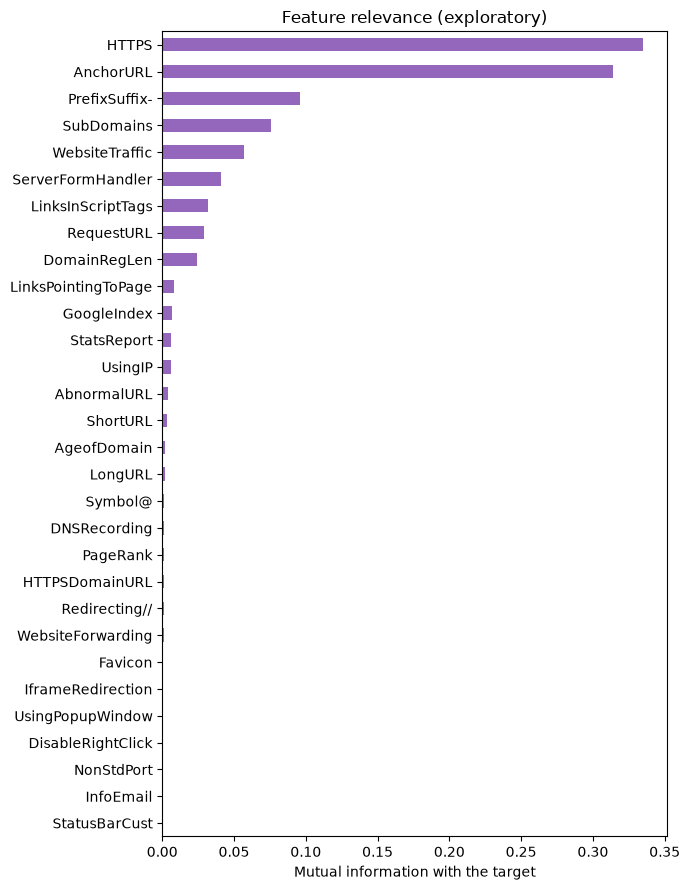

In [70]:
fig, ax = plt.subplots(figsize=(7, 9))
relevance["mutual_info"].sort_values().plot.barh(ax=ax, color="tab:purple")
ax.set_xlabel("Mutual information with the target")
ax.set_title("Feature relevance (exploratory)")
plt.tight_layout(); plt.savefig(FIG_DIR / "mutual_information.png", dpi=150); plt.show()

## 7. Redundancy between features

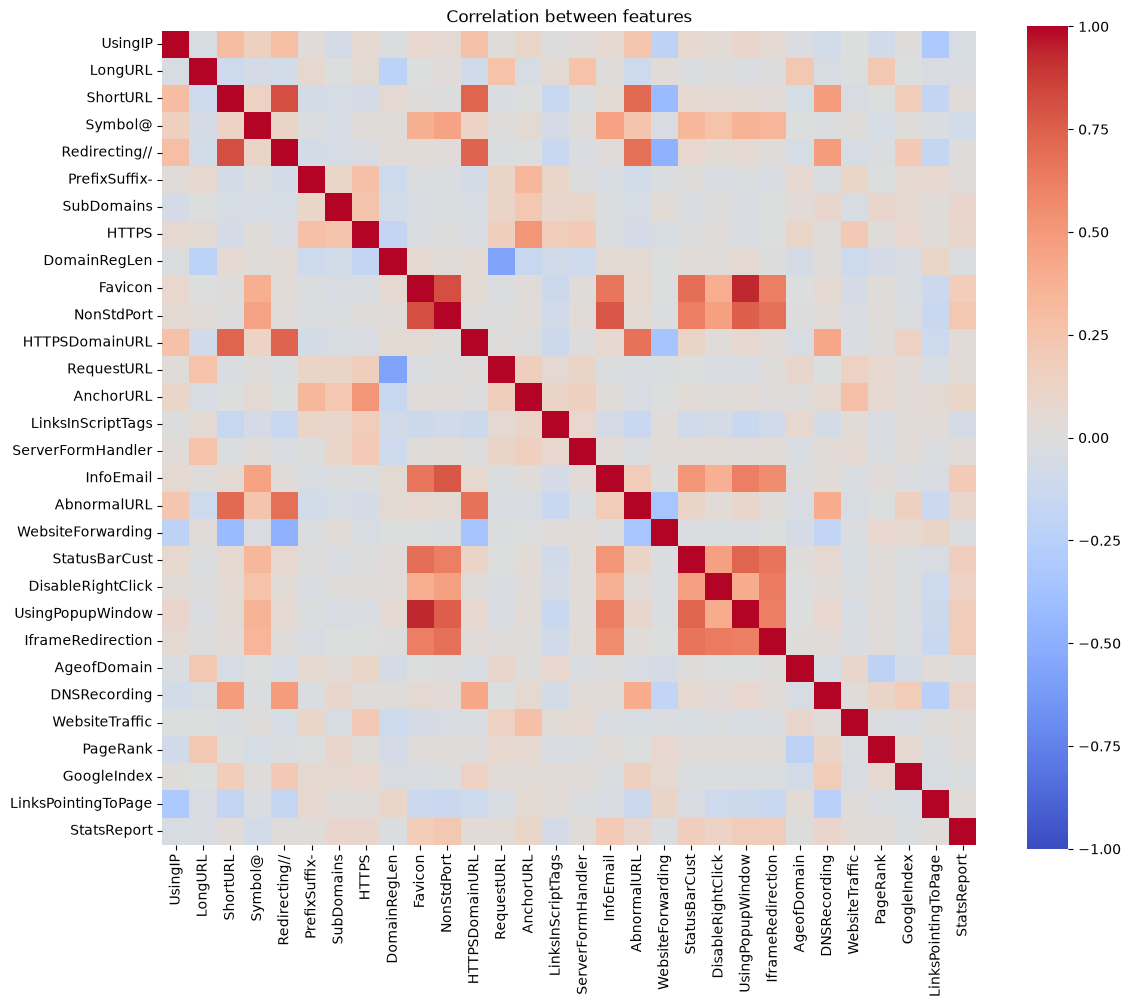

,feature_1,feature_2,r
291,Favicon,UsingPopupWindow,0.933145
64,ShortURL,Redirecting//,0.815809
280,Favicon,NonStdPort,0.812657
316,NonStdPort,InfoEmail,0.784856
321,NonStdPort,UsingPopupWindow,0.754950
131,Redirecting//,HTTPSDomainURL,0.736728
591,StatusBarCust,UsingPopupWindow,0.731814
71,ShortURL,HTTPSDomainURL,0.729916
77,ShortURL,AbnormalURL,0.711595
289,Favicon,StatusBarCust,0.690905


In [71]:
corr = df[FEATURES].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlation between features")
plt.tight_layout(); plt.savefig(FIG_DIR / "feature_correlation.png", dpi=150); plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().rename("r").rename_axis(["feature_1", "feature_2"]).reset_index()
pairs.loc[pairs["r"].abs() > 0.5].sort_values("r", key=abs, ascending=False)

## Conclusions
We drop the Index column and recode the target (1 = phishing, 0 = legitimate). The 5,205 duplicate rows are removed before splitting to avoid data leakage, which leaves 5,849 unique websites. There are no missing values, and the features are already encoded on the same −1/0/1 scale, so no imputation, encoding or scaling is needed. The classes are close to balanced (51.6% / 48.4%), so we use a stratified split without resampling. Some features are redundant (e.g. Favicon / UsingPopupWindow, r = 0.93); feature selection will be handled in the next step.